<a href="https://colab.research.google.com/github/MBeckyAlek/Formative3_ML_C1/blob/eelaf-branch/Formative3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import approx_fprime
import re
import csv

###Task 1:Guassian Probability Distribution


In [73]:
df = pd.read_csv("GaltonFamilies.csv")
heights = np.concatenate([df["father"].dropna(), df["childHeight"].dropna()]).astype(float)

np.random.seed(42)
np.random.shuffle(heights)

print("Total heights:", len(heights))
print("First five heights:", heights[:5])

FileNotFoundError: [Errno 2] No such file or directory: 'GaltonFamilies.csv'

In [ ]:
def gaussian_pdf(x, mu, sigma2):
    sigma2 = max(float(sigma2), 1e-8)
    return (1 / np.sqrt(2 * np.pi * sigma2)) * np.exp(-((x - mu) ** 2) / (2 * sigma2))


def initialise_gmm(heights):
    return np.min(heights) + 5, np.max(heights) - 5, 10.0, 10.0, 0.5, 0.5

In [ ]:
def expectation_step(heights, mu1, mu2, sigma1_2, sigma2_2, pi1, pi2):
    weighted1 = pi1 * gaussian_pdf(heights, mu1, sigma1_2)
    weighted2 = pi2 * gaussian_pdf(heights, mu2, sigma2_2)
    total = np.maximum(weighted1 + weighted2, 1e-300)

    resp1, resp2 = weighted1 / total, weighted2 / total
    log_likelihood = np.sum(np.log(total))

    return resp1, resp2, log_likelihood


def maximisation_step(heights, resp1, resp2):
    N = len(heights)
    N1, N2 = np.sum(resp1), np.sum(resp2)

    mu1 = np.sum(resp1 * heights) / N1
    mu2 = np.sum(resp2 * heights) / N2

    sigma1_2 = max(np.sum(resp1 * (heights - mu1) ** 2) / N1, 1e-8)
    sigma2_2 = max(np.sum(resp2 * (heights - mu2) ** 2) / N2, 1e-8)

    pi1, pi2 = N1 / N, N2 / N

    return mu1, mu2, sigma1_2, sigma2_2, pi1, pi2

In [ ]:
def run_em(heights, num_iterations=10):
    mu1, mu2, sigma1_2, sigma2_2, pi1, pi2 = initialise_gmm(heights)
    history = []

    for i in range(num_iterations + 1):
        resp1, resp2, ll = expectation_step(heights, mu1, mu2, sigma1_2, sigma2_2, pi1, pi2)

        history.append([i, mu1, mu2, sigma1_2, sigma2_2, pi1, pi2, ll])

        if i == num_iterations:
            break

        mu1, mu2, sigma1_2, sigma2_2, pi1, pi2 = maximisation_step(heights, resp1, resp2)

    columns = ["Iteration", "mu1", "mu2", "sigma1_squared", "sigma2_squared", "pi1", "pi2", "Log-Likelihood"]
    return pd.DataFrame(history, columns=columns), {
        "mu1": mu1, "mu2": mu2,
        "sigma1_squared": sigma1_2, "sigma2_squared": sigma2_2,
        "pi1": pi1, "pi2": pi2
    }


tracking_df, final_params = run_em(heights, 10)

display(tracking_df.head(3).round(4))

In [ ]:
plt.plot(tracking_df["Iteration"], tracking_df["Log-Likelihood"], marker="o")
plt.xlabel("Iteration")
plt.ylabel("Log-Likelihood")
plt.title("GMM Convergence")
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
x = np.linspace(heights.min() - 5, heights.max() + 5, 500)

p1 = final_params["pi1"] * gaussian_pdf(x, final_params["mu1"], final_params["sigma1_squared"])
p2 = final_params["pi2"] * gaussian_pdf(x, final_params["mu2"], final_params["sigma2_squared"])

plt.hist(heights, bins=30, density=True, alpha=0.35, label="Observed heights")
plt.plot(x, p1, label="Component 1")
plt.plot(x, p2, label="Component 2")
plt.plot(x, p1 + p2, "--", label="Combined GMM")
plt.xlabel("Height")
plt.ylabel("Density")
plt.title("Gaussian Mixture Model")
plt.legend()
plt.show()

In [74]:
def classify_height(height):
    mu1, mu2 = final_params["mu1"], final_params["mu2"]
    var1, var2 = final_params["sigma1_squared"], final_params["sigma2_squared"]
    pi1, pi2 = final_params["pi1"], final_params["pi2"]

    log_p1 = np.log(pi1) - 0.5 * np.log(2 * np.pi * var1) - ((height - mu1) ** 2) / (2 * var1)
    log_p2 = np.log(pi2) - 0.5 * np.log(2 * np.pi * var2) - ((height - mu2) ** 2) / (2 * var2)

    # Convert log values into stable probabilities
    largest = max(log_p1, log_p2)
    p1 = np.exp(log_p1 - largest)
    p2 = np.exp(log_p2 - largest)
    total = p1 + p2

    print(f"Probability of Component 1: {p1 / total:.4%}")
    print(f"Probability of Component 2: {p2 / total:.4%}")


classify_height(75)  # Replace 180 with the height your coach gives you

NameError: name 'final_params' is not defined

In [ ]:
print("Mean 1:", final_params["mu1"])
print("Mean 2:", final_params["mu2"])
print("Variance 1:", final_params["sigma1_squared"])
print("Variance 2:", final_params["sigma2_squared"])
print("Proportion 1:", final_params["pi1"])
print("Proportion 2:", final_params["pi2"])

In [ ]:
print("Minimum height:", heights.min())
print("Maximum height:", heights.max())
print("Mean height:", heights.mean())

### Part 2: Bayesian Probability

0. Load the dataset and count the number of reviews

In [81]:

DATA_PATH = "IMDB Dataset.csv"

def load_reviews(path):

    reviews = []
    with open(path, "r", encoding="utf-8", newline="") as file:
        for row in csv.DictReader(file):
            words = set(re.findall(r"[a-z']+", row["review"].lower()))
            reviews.append((words, row["sentiment"].strip().lower()))
    return reviews


reviews = load_reviews(DATA_PATH)

total_reviews = len(reviews)
positive_total = sum(1 for _, label in reviews if label == "positive")
negative_total = total_reviews - positive_total

print(f"Total reviews    : {total_reviews}")
print(f"Positive reviews : {positive_total}")
print(f"Negative reviews : {negative_total}")

# Prior: (Two factor authentication )
p_positive = positive_total / total_reviews
print(f"Prior P(Positive): {p_positive:.4f}")

Total reviews    : 50000
Positive reviews : 25000
Negative reviews : 25000
Prior P(Positive): 0.5000


1. Key Word Selection

In [ ]:
positive_words = ["fantastic", "wonderful", "stunning", "perfect"]
negative_words = ["bad", "boring", "awful", "worst"]
all_keywords = positive_words + negative_words

print("\nPositive keywords:", positive_words)
print("Negative keywords:", negative_words)

2. Choice of Conditional Probability:

We calculate the ratio of how many times the selected key words appeared on each sentiment lqabeld as postive agains negtaibve and vice versa, this to help us with the choice of the conditional probability and in this case we went with P(Positive)

In [82]:
def count_keywords(reviews, keywords):

    counts = {k: {"positive": 0, "negative": 0} for k in keywords}
    for words, label in reviews:
        for k in keywords:
            if k in words:
                counts[k][label] += 1
    return counts


keyword_counts = count_keywords(reviews, all_keywords)

print(f"\n{'keyword':<12}{'in positive':>12}{'in negative':>12}")
for k, c in keyword_counts.items():
    print(f"{k:<12}{c['positive']:>12}{c['negative']:>12}")



keyword      in positive in negative
fantastic           1079         271
wonderful           2255         522
stunning             564         160
perfect             2037         621
bad                 2947        8804
boring               591        2458
awful                281        2594
worst                409        4019


3. Computation and Presentation

For each chosen keyword, create a small table or markdown block showing the following probabilities:


In [83]:
def bayes_posterior(prior, likelihood, marginal):
    if marginal == 0:
        return None
    return likelihood * prior / marginal


def keyword_probabilities(keyword, counts, total, positive_total, p_positive):

    in_positive = counts[keyword]["positive"]
    in_any = in_positive + counts[keyword]["negative"]

    likelihood = in_positive / positive_total      # P(keyword | Positive)
    marginal = in_any / total                      # P(keyword)
    posterior = bayes_posterior(p_positive, likelihood, marginal)


    # P(Positive | keyword) = (positive reviews with keyword) / (reviews with keyword)
    if posterior is not None:
        assert abs(posterior - in_positive / in_any) < 1e-12

    return {
        "keyword": keyword,
        "prior": p_positive,
        "likelihood": likelihood,
        "marginal": marginal,
        "posterior": posterior,
    }


results = [
    keyword_probabilities(k, keyword_counts, total_reviews, positive_total, p_positive)
    for k in positive_words
]

# Markdown-style table,
columns = [
    ("Keyword", 10),
    ("Prior P(Pos)", 12),
    ("Likelihood P(k|Pos)", 19),
    ("Marginal P(k)", 13),
    ("Posterior P(Pos|k)", 18),
    ("Leans", 8),
]

def table_row(cells):
    return "| " + " | ".join(str(c).rjust(w) for c, (_, w) in zip(cells, columns)) + " |"

print()
print(table_row([title for title, _ in columns]))
print("|" + "|".join("-" * (w + 2) for _, w in columns) + "|")

for r in results:
    leans = "positive" if r["posterior"] > 0.5 else "negative"
    print(table_row([
        r["keyword"],
        f"{r['prior']:.4f}",
        f"{r['likelihood']:.4f}",
        f"{r['marginal']:.4f}",
        f"{r['posterior']:.4f}",
        leans,
    ]))



|    Keyword | Prior P(Pos) | Likelihood P(k|Pos) | Marginal P(k) | Posterior P(Pos|k) |    Leans |
|------------|--------------|---------------------|---------------|--------------------|----------|
|  fantastic |       0.5000 |              0.0432 |        0.0270 |             0.7993 | positive |
|  wonderful |       0.5000 |              0.0902 |        0.0555 |             0.8120 | positive |
|   stunning |       0.5000 |              0.0226 |        0.0145 |             0.7790 | positive |
|    perfect |       0.5000 |              0.0815 |        0.0532 |             0.7664 | positive |


# Part 4: Gradient descent

In [75]:
rng = np.random.default_rng(seed=42)

w = np.array([-1, 2]).reshape(-1, 1)
# b = np.array([1]).reshape(-1, 1)
b = np.float64(1)
alpha = 0.01
n_iterations = 100

history = {"iteration": [], "mse": [], "w1": [], "w2": [], "b": []}

data = pd.DataFrame({
    "y": [5, 6],
    "x_i1": [1, 4],
    "x_i2": [3, 10]
})

data, w.shape, b.shape

(   y  x_i1  x_i2
 0  5     1     3
 1  6     4    10,
 (2, 1),
 ())

In [76]:
X = data.copy().drop(columns=['y']).to_numpy()
y = data.copy()['y'].to_numpy().reshape(-1, 1)

X.shape, y.shape

((2, 2), (2, 1))

In [77]:
def numerical_derivative(loss, x, *args, eps=1e-7):
    """
    Numerical derivative of any scalar loss(x, *args) with respect to x
    """
    x = np.asarray(x, dtype=float)
    grad = approx_fprime(
        x.ravel(),
        lambda v, *a: loss(v.reshape(x.shape), *a),
        eps,
        *args
    )
    return grad.reshape(x.shape)

In [78]:
def forward_propagation(weights, bias, X):
    return X @ weights + bias

def mean_squared_error(y_actual, y_pred):
    return np.mean((y_actual - y_pred) ** 2)

def mse_derivative_scipy(y_actual, y_pred):
    return numerical_derivative(
        lambda p, y_a: mean_squared_error(y_a, p),
        y_pred,
        y_actual
    )

def params_gradient(w, b, X, y, eps=1e-7):
    theta = np.append(w.ravel(), b)

    def loss(t, X, y):
        w_ = t[:-1].reshape(-1, 1)
        b_ = t[-1]
        return mean_squared_error(y, forward_propagation(w_, b_, X))

    g = approx_fprime(theta, loss, eps, X, y)

    dw = g[:-1].reshape(-1, 1)
    db = g[-1]
    return dw, db

def update_params(w, b, dw, db, alpha):
    w = w - (alpha * dw)
    b = b - (alpha * db)
    return w, b

In [79]:
def run_gradient_descent(X, y, w0, b0, alpha, n_iterations):
    # Fresh copies every call, so nothing carries over between runs
    w = np.array(w0, dtype=float).reshape(-1, 1)
    b = np.float64(b0)
    history = {"iteration": [], "mse": [], "w1": [], "w2": [], "b": []}

    for i in range(n_iterations):
        y_pred = forward_propagation(w, b, X)
        mse = mean_squared_error(y, y_pred)
        gradient = mse_derivative_scipy(y, y_pred)
        dw = X.T @ gradient
        db = np.sum(gradient)

        history["iteration"].append(i)
        history["mse"].append(mse)
        history["w1"].append(w[0, 0])
        history["w2"].append(w[1, 0])
        history["b"].append(b)

        w, b = update_params(w, b, dw, db, alpha)

    return w, b, pd.DataFrame(history)


w_final, b_final, hist_df = run_gradient_descent(
    X, y, w0=[-1, 2], b0=1, alpha=0.01, n_iterations=100
)

# Sanity check: iterations should be strictly 0..99 with no repeats
# assert hist_df["iteration"].is_monotonic_increasing
# print(len(hist_df), "rows;", "starts at", hist_df.loc[0, ["w1", "w2", "b"]].tolist())

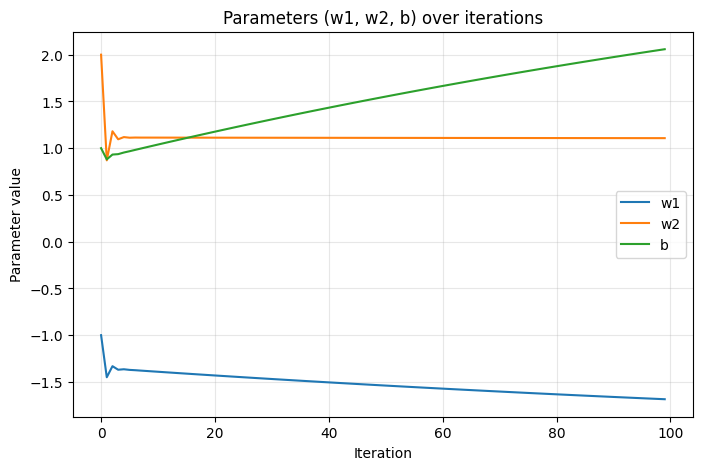

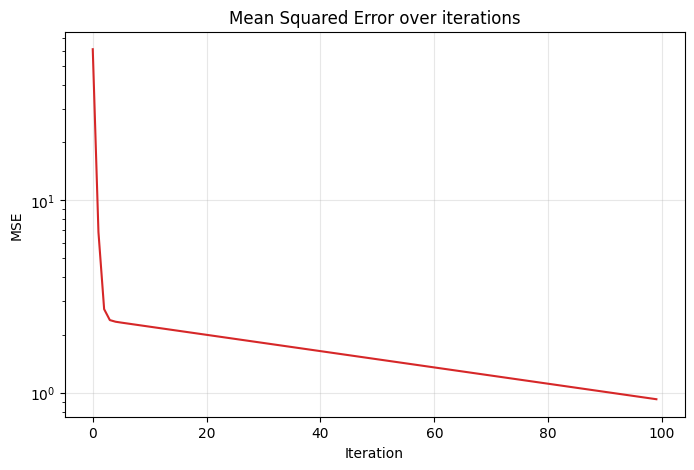

In [80]:
# Plot 1: parameters over iterations
plt.figure(figsize=(8, 5))
plt.plot(hist_df["iteration"], hist_df["w1"], label="w1")
plt.plot(hist_df["iteration"], hist_df["w2"], label="w2")
plt.plot(hist_df["iteration"], hist_df["b"], label="b")
plt.xlabel("Iteration")
plt.ylabel("Parameter value")
plt.title("Parameters (w1, w2, b) over iterations")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Plot 2: error over iterations
plt.figure(figsize=(8, 5))
plt.plot(hist_df["iteration"], hist_df["mse"], color="tab:red")
plt.xlabel("Iteration")
plt.ylabel("MSE")
plt.title("Mean Squared Error over iterations")
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.show()